In [ ]:
!pip install gensim

# Dataset Load

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import nltk
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import re
import seaborn as sns
from collections import Counter
from nltk.stem import WordNetLemmatizer
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
path = "Question Answer Classification Dataset 5[Training].csv"
qa = pd.read_csv(path)
qa.head(10)

,QA Text,Class
0,Question Title:\ni am good at web design amate...,Business & Finance
1,Question Title:\nMy daughter wants to be a Med...,Education & Reference
2,Question Title:\nIs brother Jesus our brother ...,Society & Culture
3,Question Title:\nwhat is I-20?\nQuestion Conte...,Education & Reference
4,Question Title:\nwhat is a data disk?\nQuestio...,Computers & Internet
5,Question Title:\nDon't you think that all thos...,Entertainment & Music
6,Question Title:\nwhy do people have all the se...,Society & Culture
7,Question Title:\nWho is the oldest golfer to h...,Sports
8,Question Title:\nwhat is a loan guarantor? (on...,Business & Finance
9,Question Title:\nwhat is the meaning of Magi c...,Education & Reference


In [ ]:
path2 = "Question Answer Classification Dataset 5[Training].csv"
test = pd.read_csv(path2)

In [ ]:
qa.dtypes

,0
QA Text,object
Class,object


# EDA

In [ ]:
print("Shape of dataset:", qa.shape)
print("\nColumns:", qa.columns.tolist())
print("\nData Types:\n", qa.dtypes)
print("\nMissing Values:\n", qa.isnull().sum())
print("\nFirst 5 rows:\n", qa.head())

Shape of dataset: (280003, 2)

Columns: ['QA Text', 'Class']

Data Types:
 QA Text    object
Class      object
dtype: object

Missing Values:
 QA Text    0
Class      0
dtype: int64

First 5 rows:
                                              QA Text                  Class
0  Question Title:\ni am good at web design amate...     Business & Finance
1  Question Title:\nMy daughter wants to be a Med...  Education & Reference
2  Question Title:\nIs brother Jesus our brother ...      Society & Culture
3  Question Title:\nwhat is I-20?\nQuestion Conte...  Education & Reference
4  Question Title:\nwhat is a data disk?\nQuestio...   Computers & Internet


In [ ]:
qa['Class'].value_counts()

,count
Class,
Entertainment & Music,28267
Health,28186
Sports,28074
Science & Mathematics,28039
Computers & Internet,27980
Education & Reference,27972
Business & Finance,27953
Family & Relationships,27905
Society & Culture,27881


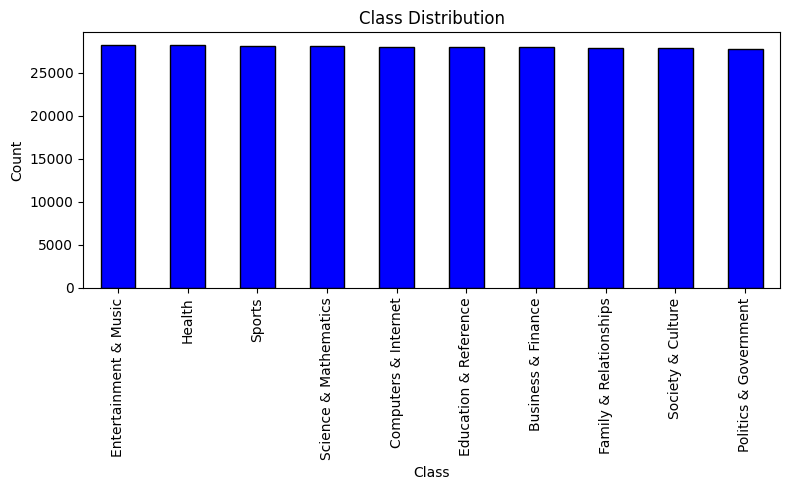

In [ ]:
class_counts = qa['Class'].value_counts()

plt.figure(figsize=(8, 5))
class_counts.plot(kind='bar', color='blue', edgecolor='black')

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

From the above class distribution bar plot, we can see that the class is distributed uniformly. So, we don't need to do upsampling or downsampling

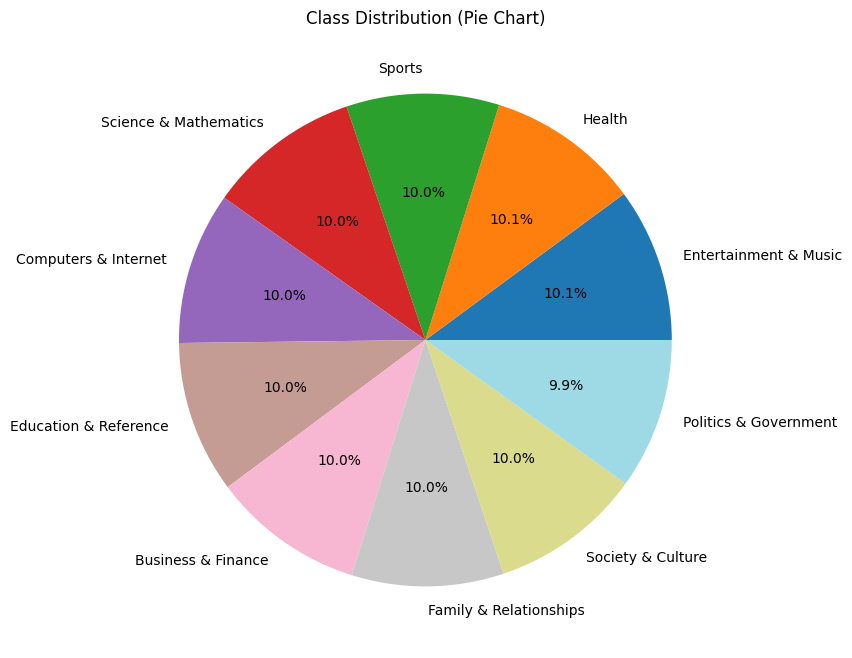

In [ ]:
qa['Class'].value_counts().plot.pie(autopct='%1.1f%%', figsize=(8,8), colormap="tab20")
plt.title("Class Distribution (Pie Chart)")
plt.ylabel("")
plt.show()

From the pie chart, it can be seen that all the classes are distributed uniformly, as the percentage of the classes are almost similar to each other.

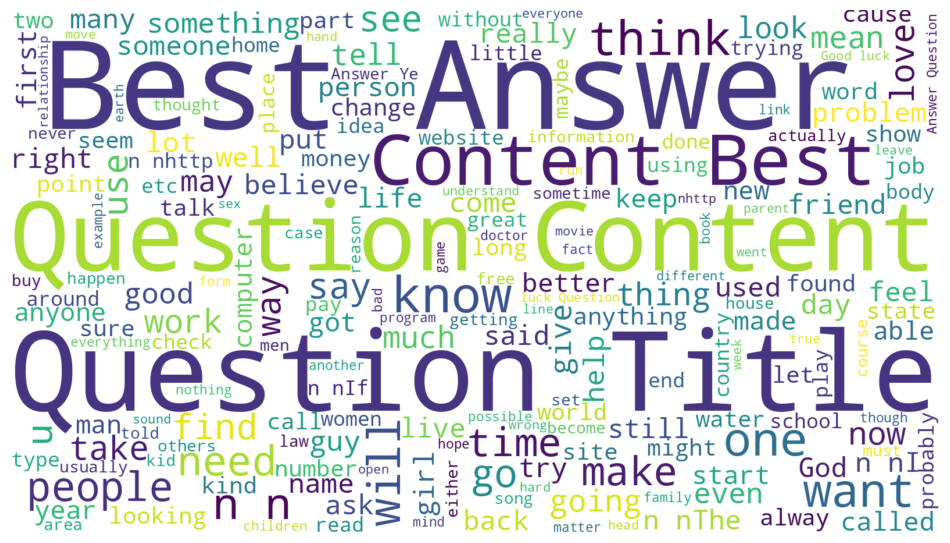

In [ ]:
text = " ".join(qa["QA Text"].astype(str))

wordcloud = WordCloud(width=1600, height=900, background_color='white').generate(text)

plt.figure(figsize=(12, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()


From the word cloud, it can be seen that **Question, Content, Best, Answer, and Title** are in high number. This means these words comes multiple times in the whole dataset.

In [ ]:
all_text = ' '.join(qa['QA Text'].tolist())
tokens = word_tokenize(all_text)

fdist = FreqDist(tokens)

most_common = fdist.most_common(20)
words = [word for word, freq in most_common]
frequencies = [freq for word, freq in most_common]

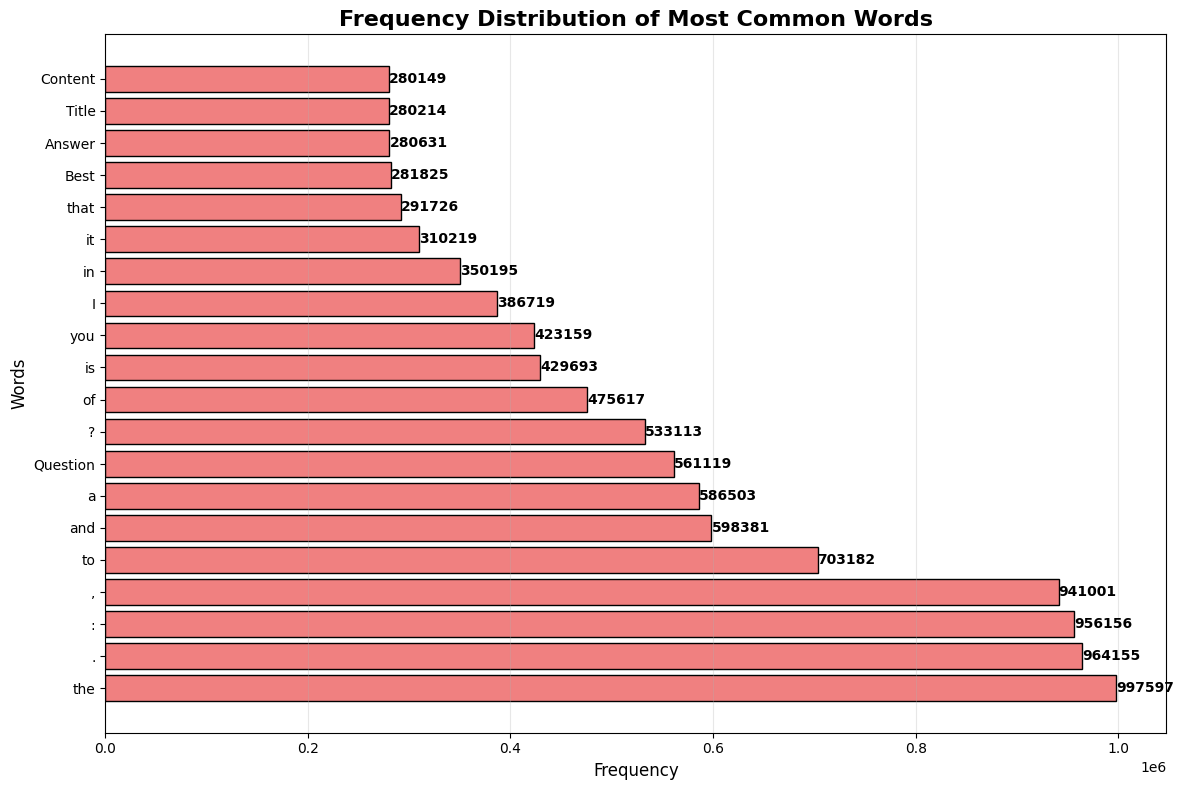

In [ ]:
plt.figure(figsize=(12, 8))
bars = plt.barh(words, frequencies, color='lightcoral', edgecolor='black')

for i, (bar, freq) in enumerate(zip(bars, frequencies)):
    plt.text(freq + 0.1, bar.get_y() + bar.get_height()/2, str(freq), ha='left', va='center', fontweight='bold')

plt.title('Frequency Distribution of Most Common Words', fontsize=16, fontweight='bold')
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Words', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

From the above Bar chart, it can be said that most common words are **the, some punctuations and to**. Also there are some stopwords and redundant words present which are in large number. We have to remove it.

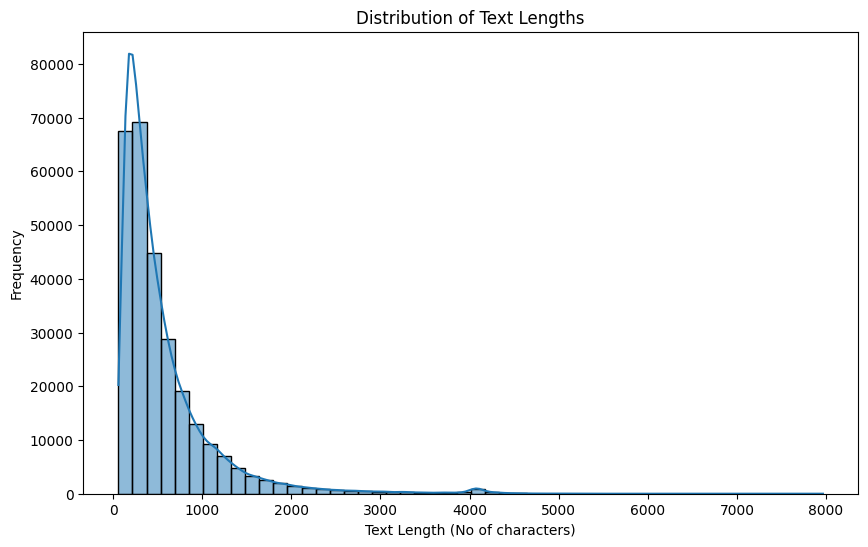

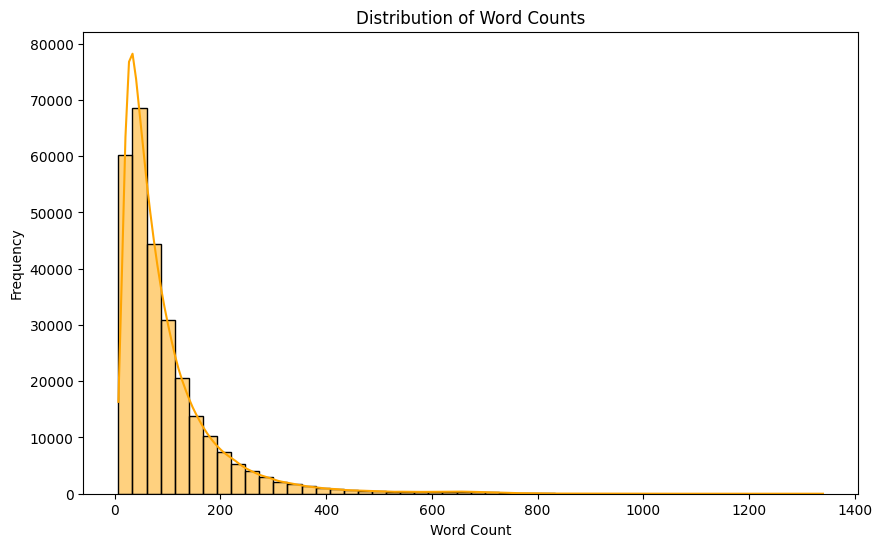

In [ ]:
qa["text_length"] = qa["QA Text"].astype(str).apply(len)
qa["word_count"] = qa["QA Text"].astype(str).apply(lambda x: len(x.split()))

plt.figure(figsize=(10,6))
sns.histplot(qa["text_length"], bins=50, kde=True)
plt.title("Distribution of Text Lengths")
plt.xlabel("Text Length (No of characters)")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10,6))
sns.histplot(qa["word_count"], bins=50, kde=True, color="orange")
plt.title("Distribution of Word Counts")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()

From the above plot, it can be said that texts which are present in the dataset, are most of them has length of 1000 or less, and the word count for most of the texts has 200 or less.

/tmp/ipython-input-620810384.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=qa, x="Class", y="word_count", palette="Set2")


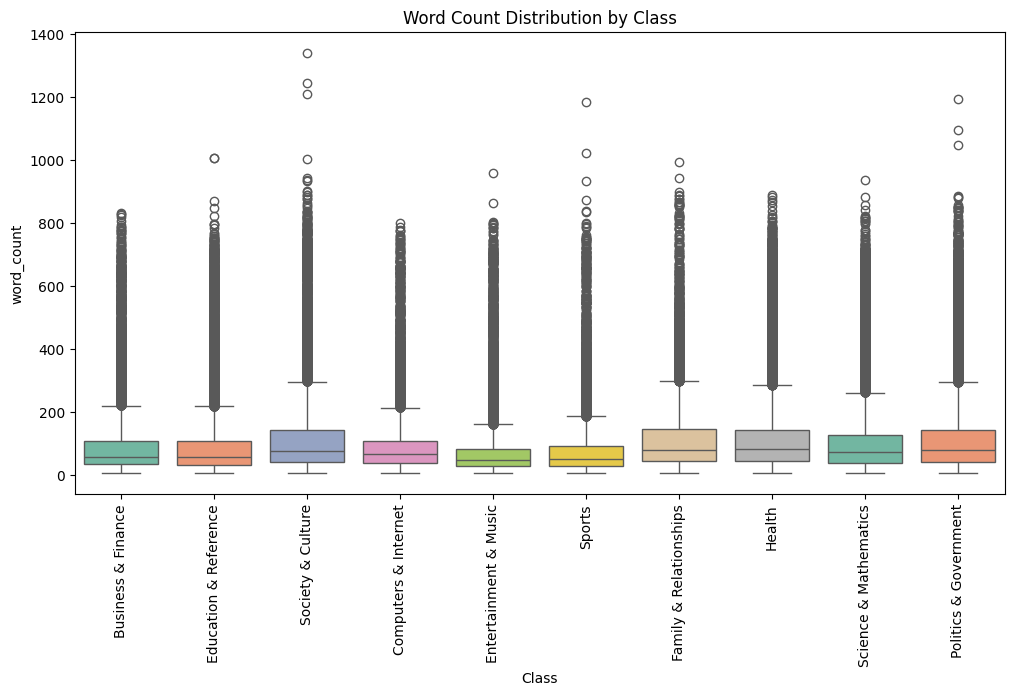

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(data=qa, x="Class", y="word_count", palette="Set2")
plt.xticks(rotation=90)
plt.title("Word Count Distribution by Class")
plt.show()

From the boxplot, it can be said that-

**Typical Length:** In most categories, the median word count for typical texts generally ranges from 50 to 250 words, with the mid-range typically falling between 100 and 200 words.

**Presence of Long Texts:** While the majority of texts are relatively concise, it is important to note that there are instances of longer texts that exist as outliers. These outliers, represented by smaller circles, can extend beyond 1,200 words, indicating that while most contributions are brief, each category may also feature some notably extensive articles.

In [ ]:
stop_words = set(stopwords.words("english"))

def clean_text(text):
    tokens = [w.lower() for w in text.split() if w.isalpha()]
    tokens = [w for w in tokens if w not in stop_words]
    return tokens

all_words = []
qa["QA Text"].astype(str).apply(lambda x: all_words.extend(clean_text(x)))

word_freq = Counter(all_words).most_common(20)

/tmp/ipython-input-3968924891.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words), palette="mako")


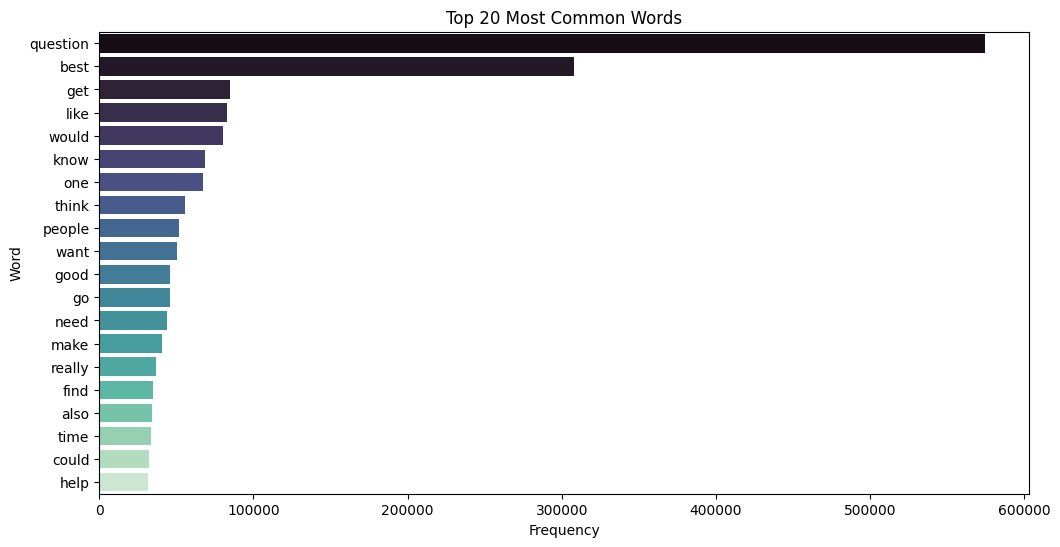

In [ ]:
words, counts = zip(*word_freq)
plt.figure(figsize=(12,6))
sns.barplot(x=list(counts), y=list(words), palette="mako")
plt.title("Top 20 Most Common Words")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

After cleaning the punctuation and other unnecessary words like stopwords, the barplot shows that there present a word **question and best** in large numbers.

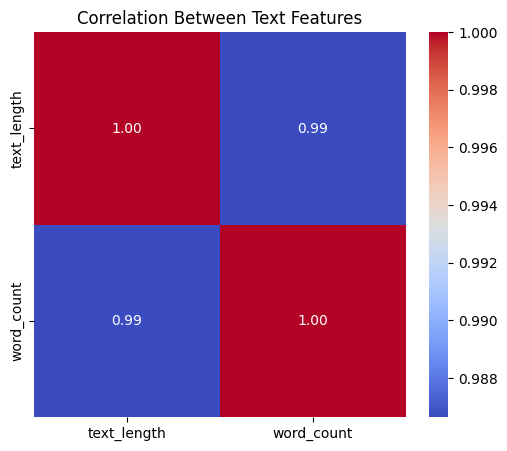

In [ ]:
plt.figure(figsize=(6,5))
sns.heatmap(qa[["text_length", "word_count"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Text Features")
plt.show()

The values of 1.00: These are located on the diagonal and represent the correlation of a feature with itself, such as text_length with text_length and word_count with word_count. This reflects a perfect correlation, resulting in a value of 1.00.

The value of 0.99: This is a particularly significant figure, as it indicates the correlation between text_length and word_count. A correlation coefficient of 0.99 suggests a very strong positive correlation.

In other words, this relationship indicates that as the word_count of a text increases, the text_length (the total number of characters) also tends to increase in a highly predictable and nearly linear manner.

In [ ]:
qa.head()

,QA Text,Class
0,Question Title:\ni am good at web design amate...,Business & Finance
1,Question Title:\nMy daughter wants to be a Med...,Education & Reference
2,Question Title:\nIs brother Jesus our brother ...,Society & Culture
3,Question Title:\nwhat is I-20?\nQuestion Conte...,Education & Reference
4,Question Title:\nwhat is a data disk?\nQuestio...,Computers & Internet


In [ ]:
qa.tail()

,QA Text,Class
279998,Question Title:\nWhat is the best way to learn...,Education & Reference
279999,Question Title:\nWhat is the current payroll o...,Sports
280000,Question Title:\nWhat's your opinion on the ba...,Sports
280001,Question Title:\nWhat do you think will happen...,Society & Culture
280002,Question Title:\nwhat am i thinking right now?...,Business & Finance


After seeing the first and last 5 rows, there are some repeatative and unnecessary words present in the dataset, such as, "Question, Title, \n". We have to remove it.

# Data Preprocessing

In [ ]:
nltk.download("stopwords")
nltk.download("punkt")
nltk.download("wordnet")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
qa.dropna(subset=["QA Text", "Class"], inplace=True)
qa.reset_index(drop=True, inplace=True)

In [ ]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\b(question|title|\n)\b", "", text)
    tokens = nltk.word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [t for t in tokens if t.isalnum()]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(tokens)

qa["clean_text"] = qa["QA Text"].apply(clean_text)

In [ ]:
qa['Cleaned_Text_length'] = qa['clean_text'].apply(len)

In [ ]:
label_encoder = LabelEncoder()
qa["label"] = label_encoder.fit_transform(qa["Class"])

print("Class Mapping:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

Class Mapping: {'Business & Finance': 0, 'Computers & Internet': 1, 'Education & Reference': 2, 'Entertainment & Music': 3, 'Family & Relationships': 4, 'Health': 5, 'Politics & Government': 6, 'Science & Mathematics': 7, 'Society & Culture': 8, 'Sports': 9}


In [ ]:
test["clean_text"] = test["QA Text"].apply(clean_text)
test["label"] = label_encoder.transform(test["Class"])

In [ ]:
qa.head()

,QA Text,Class,clean_text,Cleaned_Text_length,label
0,Question Title:\ni am good at web design amate...,Business & Finance,good web design amateurly earn money job conte...,259,0
1,Question Title:\nMy daughter wants to be a Med...,Education & Reference,daughter want medical illustrator anyone know ...,1449,2
2,Question Title:\nIs brother Jesus our brother ...,Society & Culture,brother jesus brother king content best answer...,85,8
3,Question Title:\nwhat is I-20?\nQuestion Conte...,Education & Reference,contentstudents need admitted university hell ...,169,2
4,Question Title:\nwhat is a data disk?\nQuestio...,Computers & Internet,data disk contenti heard possible save file da...,286,1


In [ ]:
qa.shape

(280003, 5)

# Model

**ML Model: Logistic Regression**

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB #Angshu start
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [ ]:
train_texts, val_texts, train_labels, val_labels = train_test_split(qa["clean_text"], qa["label"],
    test_size=0.2, random_state=42, stratify=qa["label"])

test_texts, test_labels = test["clean_text"], test["label"]

In [ ]:
def train_evaluate(vectorizer, model, X_train, y_train, X_val, y_val, X_test, y_test, name="Model"):
    X_train_vec = vectorizer.fit_transform(X_train)
    X_val_vec   = vectorizer.transform(X_val)
    X_test_vec  = vectorizer.transform(X_test)

    model.fit(X_train_vec, y_train)

    val_preds = model.predict(X_val_vec)
    val_acc   = accuracy_score(y_val, val_preds)
    val_f1    = f1_score(y_val, val_preds, average="macro")

    test_preds = model.predict(X_test_vec)
    test_acc   = accuracy_score(y_test, test_preds)
    test_f1    = f1_score(y_test, test_preds, average="macro")
    test_report = classification_report(y_test, test_preds, output_dict=True)
    test_cm     = confusion_matrix(y_test, test_preds)

    return {
        "name": name,
        "val_accuracy": val_acc,
        "val_f1_macro": val_f1,
        "test_accuracy": test_acc,
        "test_f1_macro": test_f1,
        "report": test_report,
        "cm": test_cm,
        "preds": test_preds
    }

In [ ]:
bow_vectorizer = CountVectorizer(ngram_range=(1,3), max_features=100000, binary=False)
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1,3), max_features=100000, sublinear_tf=True)

logreg = LogisticRegression(C=1.0, solver="liblinear", max_iter=500, class_weight="balanced")
multinomial_nb = MultinomialNB(alpha=0.10129197956845731) #angshu 2nd

For bow_vectorizer and tfidf_vectorizer, I used ngram_range=(1, 2) and the max_features=50000, but this gives me the accuracy and F1-score for both validation and test case with slightly low values, in comparison to the current hyperparameters. Again, the dataset has the data of QA type, so the frequency of the data matters (repeated words gives a strong signal), as a result, I use binary=False, which capture the frequency of the data. For tfidf_vectorizer, the sublinear_tf=True, because it applies logarithmic scaling to the term frequency and prevents very frequent words from dominating.

For Logistic Regression,
1. C=1.0 is the default sweet spot — balances underfitting and overfitting.
2. solver="liblinear" is more stable for text classification compared to "lbfgs" when vocab size is large.
3. max_iter=500 ensures convergence when training with high-dimensional sparse matrices.
4. class_weights="balanced" adjusts weights inversely proportional to class frequencies. Though my dataset is well balanced, I still use it to ensure the balance in classes.

Rigoursly testing code reaveals the alpha value of for multinommial navie bayes is 0.10129197956845731, also prior edas show that the datset is balanced hence class_prior remains deafult.

In [ ]:
#Rigoursly testing code reaveals the alpha value of for multinommial navie bayes is 0.10129197956845731, also prior edas show that the datset is balanced hence class_prior remains deafult.
#By angshu
results = []
results.append(
    train_evaluate(bow_vectorizer, logreg, train_texts, train_labels,
                   val_texts, val_labels,
                   test_texts, test_labels, name="BoW + Logistic Regression")
)

results.append(
    train_evaluate(tfidf_vectorizer, logreg, train_texts, train_labels,
                   val_texts, val_labels,
                   test_texts, test_labels, name="TF-IDF + Logistic Regression")
)

In [ ]:
#angshu 3rd
results_multinomialNB = []
results_multinomialNB.append(
    train_evaluate(bow_vectorizer, multinomial_nb, train_texts, train_labels,
                   val_texts, val_labels,
                   test_texts, test_labels, name="BoW + Naive Bayes") #wrong print statement
)

results_multinomialNB.append(
    train_evaluate(tfidf_vectorizer, multinomial_nb, train_texts, train_labels,
                   val_texts, val_labels,
                   test_texts, test_labels, name="TF-IDF + Navie Bayes") #wrong print statement
)

In [ ]:
perf_df = pd.DataFrame([{
    "Model": r["name"],
    "Val Accuracy": r["val_accuracy"],
    "Val F1 (macro)": r["val_f1_macro"],
    "Test Accuracy": r["test_accuracy"],
    "Test F1 (macro)": r["test_f1_macro"]
} for r in results])

print("\nPerformance Comparison for logreg:")
perf_df


Performance Comparison:


,Model,Val Accuracy,Val F1 (macro),Test Accuracy,Test F1 (macro)
0,BoW + Logistic Regression,0.661238,0.660069,0.661744,0.660746
1,TF-IDF + Logistic Regression,0.701380,0.698349,0.702428,0.699626


In [ ]:
#angshu 4th
perf_df_NB = pd.DataFrame([{
    "Model": r["name"],
    "Val Accuracy": r["val_accuracy"],
    "Val F1 (macro)": r["val_f1_macro"],
    "Test Accuracy": r["test_accuracy"],
    "Test F1 (macro)": r["test_f1_macro"]
} for r in results_multinomialNB])

print("\nPerformance Comparison for Navie Bayes:")
perf_df_NB


Performance Comparison for Navie Bayes:


,Model,Val Accuracy,Val F1 (macro),Test Accuracy,Test F1 (macro)
0,BoW + Naive Bayes,0.679649,0.677372,0.727517,0.725158
1,TF-IDF + Navie Bayes,0.683524,0.680567,0.744581,0.742120



=== BoW + Logistic Regression ===
Classification Report (Test):
              precision    recall  f1-score       support
0              0.496534  0.477500  0.486831   6000.000000
1              0.808621  0.831667  0.819982   6000.000000
2              0.473799  0.470167  0.471976   6000.000000
3              0.647446  0.671833  0.659414   6000.000000
4              0.670480  0.703451  0.686570   5999.000000
5              0.727899  0.739667  0.733736   6000.000000
6              0.719107  0.692500  0.705553   6000.000000
7              0.657576  0.679167  0.668197   6000.000000
8              0.541153  0.505167  0.522541   6000.000000
9              0.859076  0.846333  0.852657   6000.000000
accuracy       0.661744  0.661744  0.661744      0.661744
macro avg      0.660169  0.661745  0.660746  59999.000000
weighted avg   0.660169  0.661744  0.660745  59999.000000


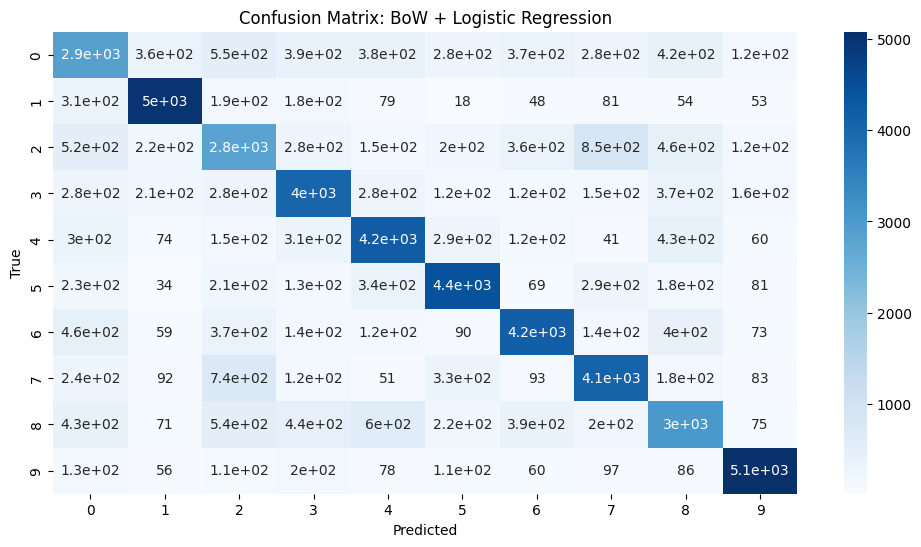


=== TF-IDF + Logistic Regression ===
Classification Report (Test):
              precision    recall  f1-score       support
0              0.572492  0.512667  0.540930   6000.000000
1              0.814068  0.854500  0.833794   6000.000000
2              0.559269  0.504833  0.530659   6000.000000
3              0.681691  0.690667  0.686150   6000.000000
4              0.684702  0.769962  0.724833   5999.000000
5              0.742047  0.785333  0.763077   6000.000000
6              0.761494  0.750833  0.756126   6000.000000
7              0.697379  0.749333  0.722423   6000.000000
8              0.608066  0.552833  0.579136   6000.000000
9              0.865011  0.853333  0.859132   6000.000000
accuracy       0.702428  0.702428  0.702428      0.702428
macro avg      0.698622  0.702429  0.699626  59999.000000
weighted avg   0.698622  0.702428  0.699626  59999.000000


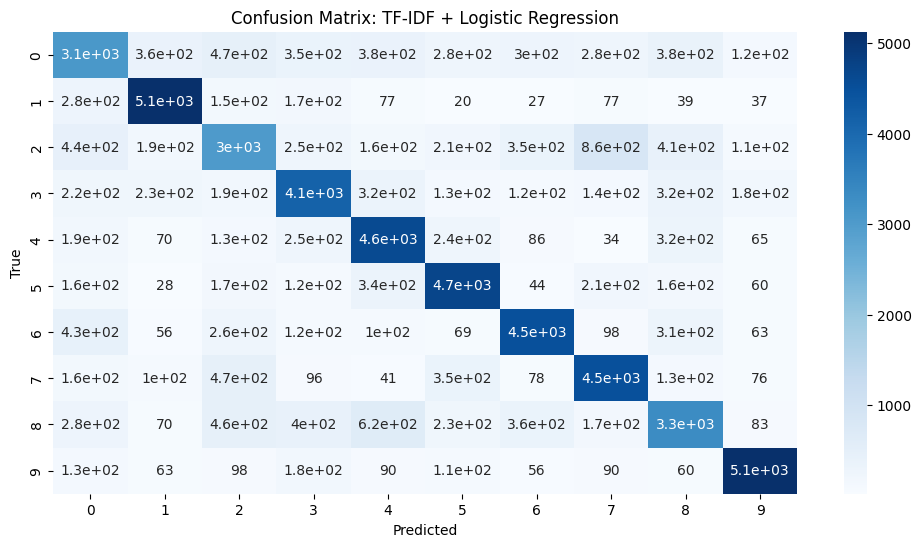

In [ ]:
for r in results:
    print(f"\n=== {r['name']} ===")
    print("Classification Report (Test):")
    print(pd.DataFrame(r["report"]).transpose())

    # Plot confusion matrix
    plt.figure(figsize=(12,6))
    sns.heatmap(r["cm"], annot=True, cmap="Blues")
    plt.title(f"Confusion Matrix: {r['name']}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

For BoW + Logistic Regression,
Most classes exhibit strong diagonal dominance, indicating that many samples are predicted correctly. However, there are still significant misclassifications among classes.

In summary, the Bag of Words (BoW) approach performs well overall, but it tends to overfit frequent words, leading to higher misclassification rates when there is considerable vocabulary overlap between classes.You can see that most classes have strong diagonal dominance, meaning many samples are correctly predicted.

Overall: BoW works well but tends to overfit frequent words, so misclassifications happen when vocabulary overlap between classes is high.

For TF-IDF + Logistic Regression,
Diagonal values are slightly higher than BoW for most classes (e.g., class 2 ~3000 vs. ~2800 in BoW, class 4 ~4600 vs. ~4200, class 5 ~4700 vs. ~4400, etc.), showing better discrimination.

Misclassifications across classes are lower compared to BoW, especially for frequently confused categories (like class 2 and class 3).

TF-IDF helps because it down-weights common words and highlights rare but informative terms, making the classifier more robust.

Therefore, TF-IDF + Logistic Regression is performing better overall than BoW + Logistic Regression in your dataset.

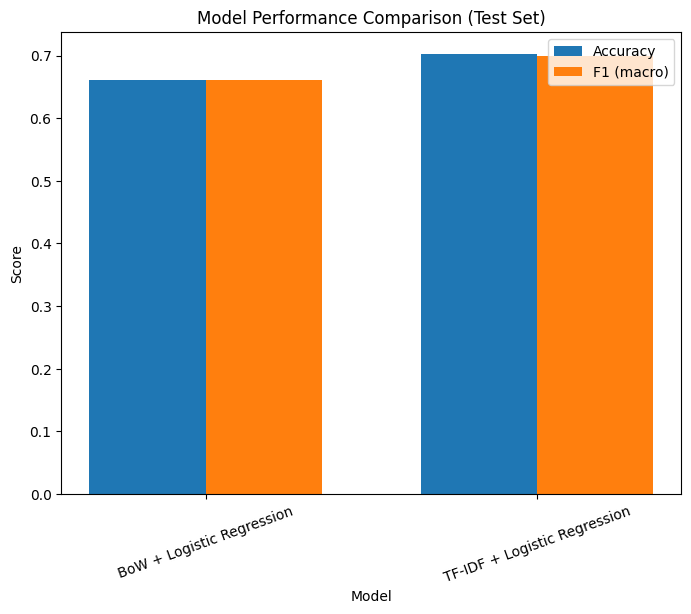

In [ ]:
plt.figure(figsize=(8,6))
bar_width = 0.35
index = np.arange(len(results))

plt.bar(index, [r["test_accuracy"] for r in results], bar_width, label="Accuracy")
plt.bar(index + bar_width, [r["test_f1_macro"] for r in results], bar_width, label="F1 (macro)")

plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(index + bar_width/2, [r["name"] for r in results], rotation=20)
plt.legend()
plt.title("Model Performance Comparison (Test Set)")
plt.show()


=== BoW + Naive Bayes ===
Classification Report (Test):
              precision    recall  f1-score        support
0              0.624631  0.545416  0.582342   27953.000000
1              0.822554  0.870443  0.845821   27980.000000
2              0.618977  0.554340  0.584878   27972.000000
3              0.649088  0.771571  0.705049   28267.000000
4              0.678966  0.803834  0.736143   27905.000000
5              0.799511  0.788335  0.793883   28186.000000
6              0.794709  0.761083  0.777532   27746.000000
7              0.743676  0.745533  0.744604   28039.000000
8              0.671629  0.584090  0.624808   27881.000000
9              0.864235  0.848935  0.856517   28074.000000
accuracy       0.727517  0.727517  0.727517       0.727517
macro avg      0.726798  0.727358  0.725158  280003.000000
weighted avg   0.726810  0.727517  0.725242  280003.000000


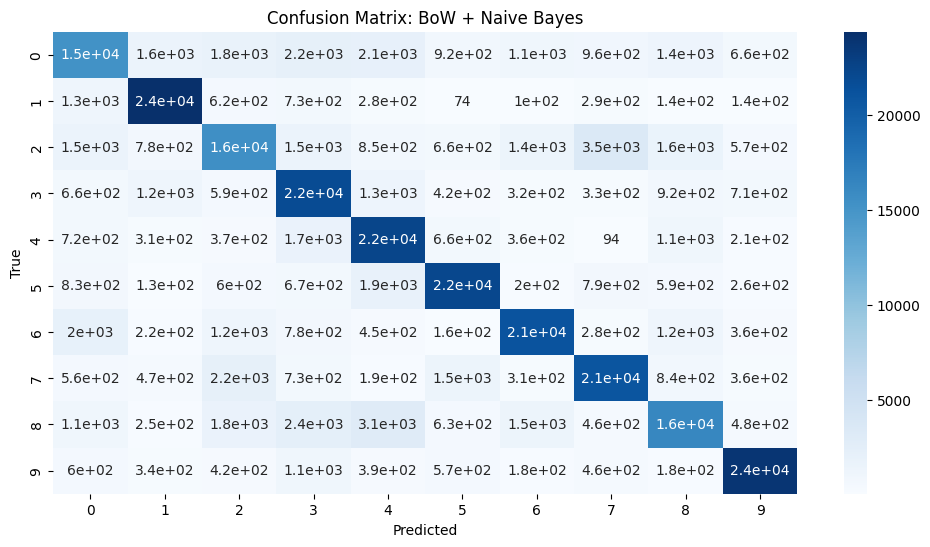


=== TF-IDF + Navie Bayes ===
Classification Report (Test):
              precision    recall  f1-score        support
0              0.647664  0.564948  0.603485   27953.000000
1              0.829439  0.879092  0.853544   27980.000000
2              0.657555  0.563313  0.606797   27972.000000
3              0.709218  0.762408  0.734852   28267.000000
4              0.689333  0.826089  0.751540   27905.000000
5              0.792415  0.810970  0.801585   28186.000000
6              0.790040  0.793628  0.791830   27746.000000
7              0.744524  0.772246  0.758132   28039.000000
8              0.674242  0.623579  0.647921   27881.000000
9              0.895889  0.848436  0.871517   28074.000000
accuracy       0.744581  0.744581  0.744581       0.744581
macro avg      0.743032  0.744471  0.742120  280003.000000
weighted avg   0.743096  0.744581  0.742210  280003.000000


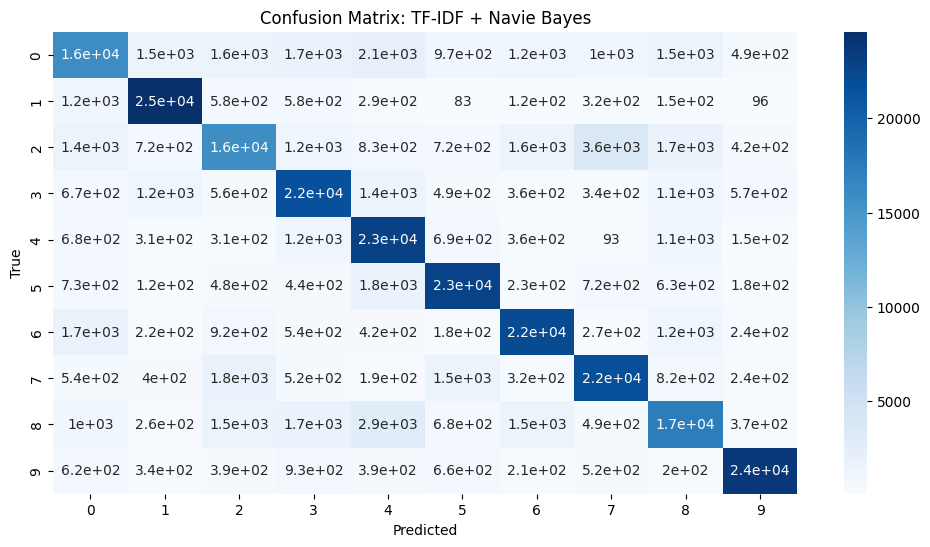

In [ ]:
#angshu 4th
for r in results_multinomialNB:
    print(f"\n=== {r['name']} ===")
    print("Classification Report (Test):")
    print(pd.DataFrame(r["report"]).transpose())

    # Plot confusion matrix
    plt.figure(figsize=(12,6))
    sns.heatmap(r["cm"], annot=True, cmap="Blues")
    plt.title(f"Confusion Matrix: {r['name']}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

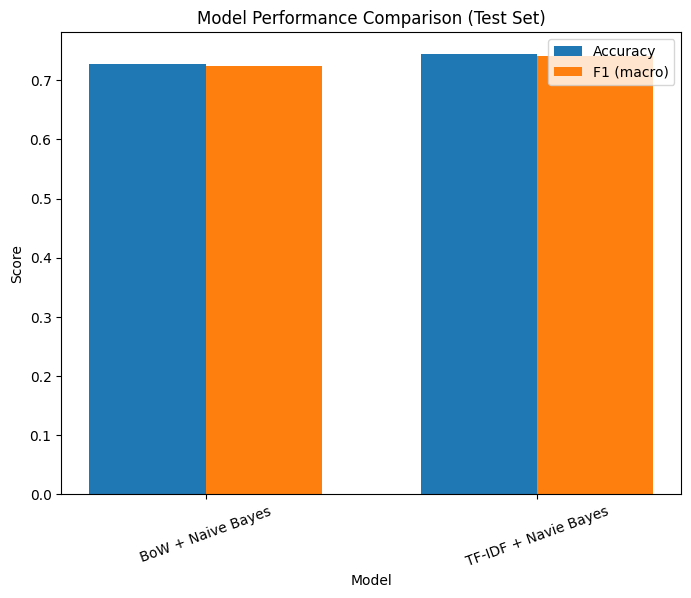

In [ ]:
#angshu 5th
plt.figure(figsize=(8,6))
bar_width = 0.35
index = np.arange(len(results_multinomialNB))

plt.bar(index, [r["test_accuracy"] for r in results_multinomialNB], bar_width, label="Accuracy")
plt.bar(index + bar_width, [r["test_f1_macro"] for r in results_multinomialNB], bar_width, label="F1 (macro)")

plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(index + bar_width/2, [r["name"] for r in results_multinomialNB], rotation=20)
plt.legend()
plt.title("Model Performance Comparison (Test Set)")
plt.show()

**Neural Network Model**

**Deep Neural Network**

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.decomposition import TruncatedSVD

In [ ]:
y_train_enc = train_labels
y_val_enc   = val_labels
y_test_enc  = test_labels

In [ ]:
X_train_bow = bow_vectorizer.fit_transform(train_texts)
X_val_bow   = bow_vectorizer.transform(val_texts)
X_test_bow  = bow_vectorizer.transform(test_texts)

svd = TruncatedSVD(n_components=300)
X_train_bow = svd.fit_transform(X_train_bow)
X_val_bow   = svd.transform(X_val_bow)
X_test_bow  = svd.transform(X_test_bow)

In [ ]:
X_train_tfidf = tfidf_vectorizer.fit_transform(train_texts)
X_val_tfidf   = tfidf_vectorizer.transform(val_texts)
X_test_tfidf  = tfidf_vectorizer.transform(test_texts)

svd = TruncatedSVD(n_components=300)
X_train_tfidf = svd.fit_transform(X_train_tfidf)
X_val_tfidf   = svd.transform(X_val_tfidf)
X_test_tfidf  = svd.transform(X_test_tfidf)

In [ ]:
def build_dnn(input_dim, num_classes):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(512, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(256, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(128, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=3e-4),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

In [ ]:
def run_experiment(name, X_train, y_train, X_val, y_val, X_test, y_test):

    callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    ]

    model = build_dnn(X_train.shape[1], len(np.unique(y_train)))
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20, batch_size=256, verbose=2, callbacks=callbacks
    )

    # Predictions
    y_pred = np.argmax(model.predict(X_test, batch_size=512, verbose=0), axis=1)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average="macro")
    f1_weighted = f1_score(y_test, y_pred, average="weighted")
    report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    plt.title(f"{name} Confusion Matrix")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.show()

    # Accuracy / Loss curves
    plt.figure()
    plt.plot(history.history["accuracy"], label="Train Accuracy")
    plt.plot(history.history["val_accuracy"], label="Val Accuracy")
    plt.title(f"{name} Accuracy")
    plt.xlabel("Epochs"); plt.ylabel("Accuracy"); plt.legend(); plt.show()

    plt.figure()
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Val Loss")
    plt.title(f"{name} Loss")
    plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.legend(); plt.show()

    print(f"\n{name} Results")
    print(f"Accuracy: {acc:.4f}")
    print(f"F1-macro: {f1_macro:.4f}")
    print(f"F1-weighted: {f1_weighted:.4f}")
    print(report)

    return {"Model": name, "Accuracy": acc, "F1-macro": f1_macro, "F1-weighted": f1_weighted}

Epoch 1/20
876/876 - 10s - 11ms/step - accuracy: 0.4544 - loss: 1.6762 - val_accuracy: 0.5907 - val_loss: 1.2736
Epoch 2/20
876/876 - 3s - 3ms/step - accuracy: 0.5664 - loss: 1.3418 - val_accuracy: 0.6071 - val_loss: 1.2077
Epoch 3/20
876/876 - 3s - 3ms/step - accuracy: 0.5880 - loss: 1.2710 - val_accuracy: 0.6139 - val_loss: 1.1880
Epoch 4/20
876/876 - 3s - 3ms/step - accuracy: 0.6004 - loss: 1.2349 - val_accuracy: 0.6190 - val_loss: 1.1684
Epoch 5/20
876/876 - 3s - 3ms/step - accuracy: 0.6075 - loss: 1.2107 - val_accuracy: 0.6220 - val_loss: 1.1622
Epoch 6/20
876/876 - 3s - 3ms/step - accuracy: 0.6119 - loss: 1.1928 - val_accuracy: 0.6245 - val_loss: 1.1537
Epoch 7/20
876/876 - 3s - 3ms/step - accuracy: 0.6178 - loss: 1.1760 - val_accuracy: 0.6274 - val_loss: 1.1441
Epoch 8/20
876/876 - 3s - 3ms/step - accuracy: 0.6204 - loss: 1.1629 - val_accuracy: 0.6270 - val_loss: 1.1389
Epoch 9/20
876/876 - 3s - 3ms/step - accuracy: 0.6250 - loss: 1.1504 - val_accuracy: 0.6288 - val_loss: 1.1342

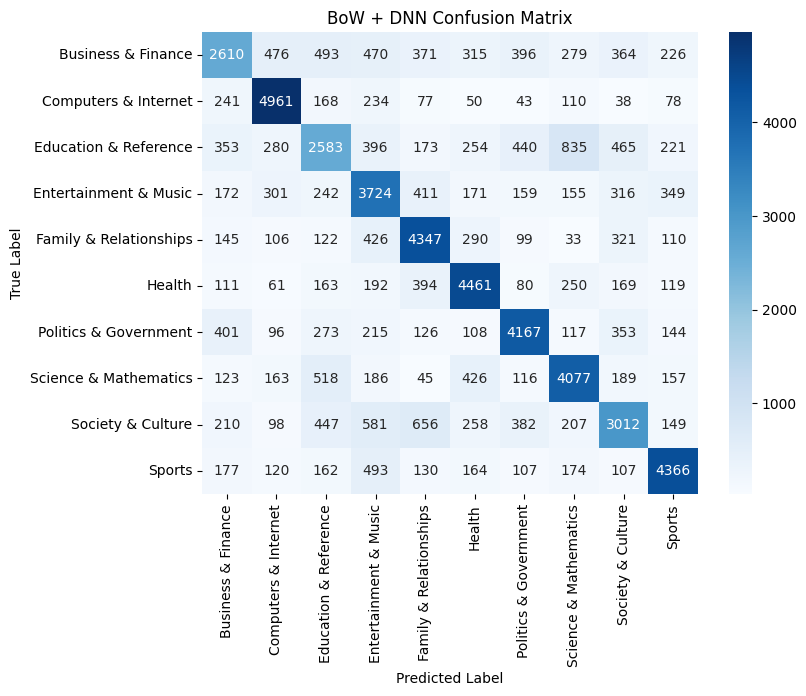

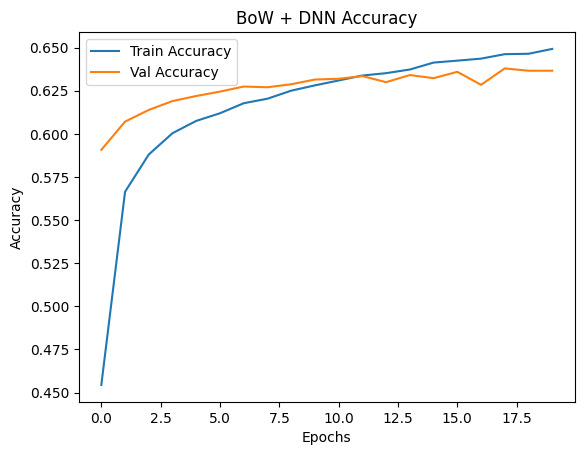

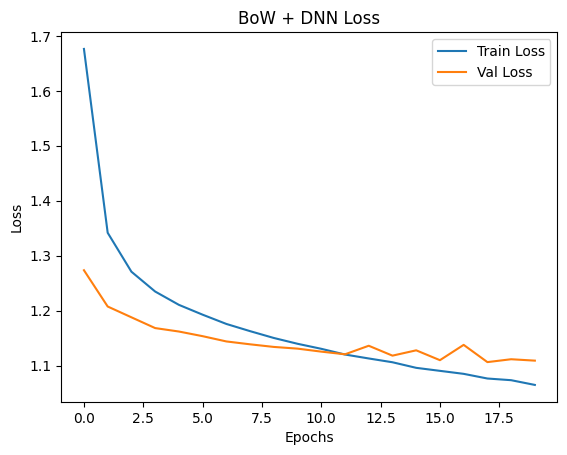


BoW + DNN Results
Accuracy: 0.6385
F1-macro: 0.6340
F1-weighted: 0.6340
                        precision    recall  f1-score   support

    Business & Finance       0.57      0.43      0.50      6000
  Computers & Internet       0.74      0.83      0.78      6000
 Education & Reference       0.50      0.43      0.46      6000
 Entertainment & Music       0.54      0.62      0.58      6000
Family & Relationships       0.65      0.72      0.68      5999
                Health       0.69      0.74      0.71      6000
 Politics & Government       0.70      0.69      0.70      6000
 Science & Mathematics       0.65      0.68      0.67      6000
     Society & Culture       0.56      0.50      0.53      6000
                Sports       0.74      0.73      0.73      6000

              accuracy                           0.64     59999
             macro avg       0.63      0.64      0.63     59999
          weighted avg       0.63      0.64      0.63     59999

Epoch 1/20
876/876 - 12s - 1

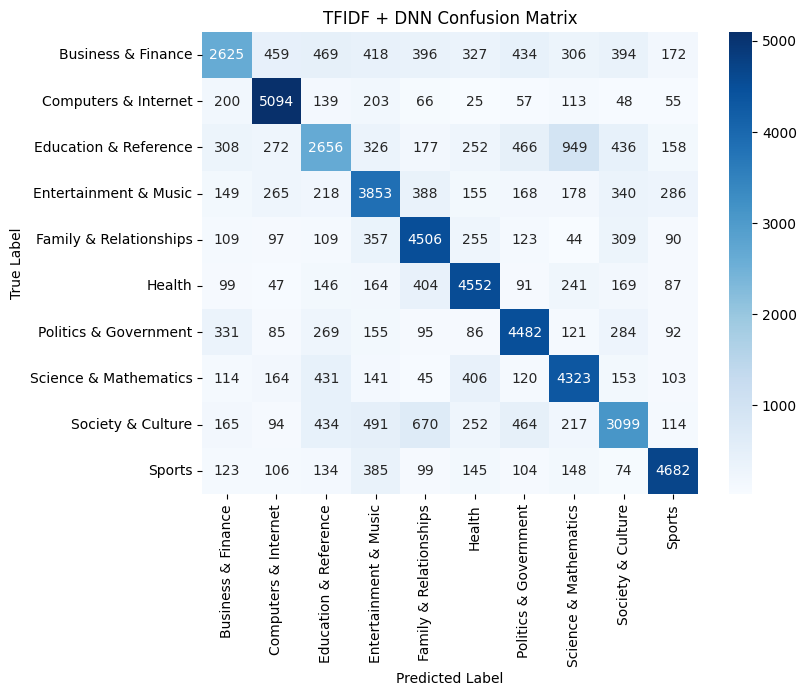

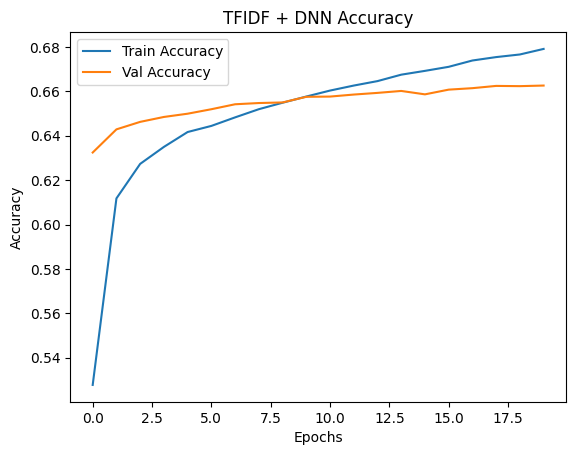

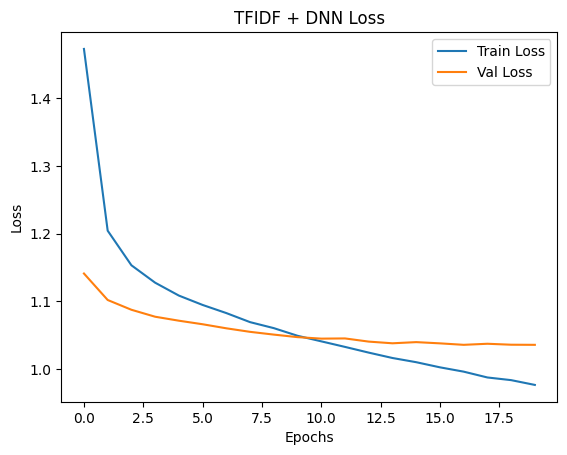


TFIDF + DNN Results
Accuracy: 0.6645
F1-macro: 0.6589
F1-weighted: 0.6589
                        precision    recall  f1-score   support

    Business & Finance       0.62      0.44      0.51      6000
  Computers & Internet       0.76      0.85      0.80      6000
 Education & Reference       0.53      0.44      0.48      6000
 Entertainment & Music       0.59      0.64      0.62      6000
Family & Relationships       0.66      0.75      0.70      5999
                Health       0.71      0.76      0.73      6000
 Politics & Government       0.69      0.75      0.72      6000
 Science & Mathematics       0.65      0.72      0.68      6000
     Society & Culture       0.58      0.52      0.55      6000
                Sports       0.80      0.78      0.79      6000

              accuracy                           0.66     59999
             macro avg       0.66      0.66      0.66     59999
          weighted avg       0.66      0.66      0.66     59999



In [ ]:
bow_results   = run_experiment("BoW + DNN", X_train_bow, y_train_enc, X_val_bow, y_val_enc, X_test_bow, y_test_enc)
tfidf_results = run_experiment("TFIDF + DNN", X_train_tfidf, y_train_enc, X_val_tfidf, y_val_enc, X_test_tfidf, y_test_enc)

In [ ]:
results_df = pd.DataFrame([bow_results, tfidf_results])
print(results_df)

         Model  Accuracy  F1-macro  F1-weighted
0    BoW + DNN  0.638477  0.634030     0.634029
1  TFIDF + DNN  0.664544  0.658866     0.658866


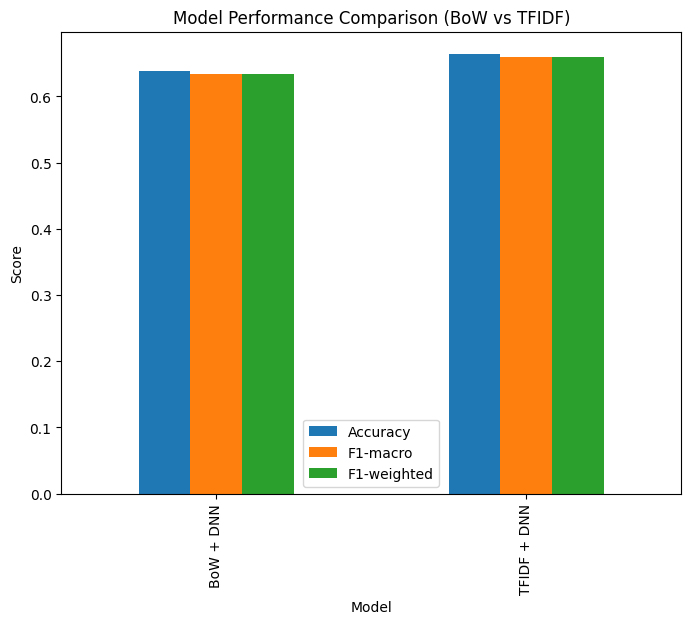

In [ ]:
results_df.set_index("Model")[["Accuracy","F1-macro","F1-weighted"]].plot(kind="bar", figsize=(8,6))
plt.title("Model Performance Comparison (BoW vs TFIDF)")
plt.ylabel("Score")
plt.show()

**GRU & Bidirectional GRU**

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, GRU, Bidirectional, Dense, Dropout, Lambda, Multiply, Softmax
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from pathlib import Path
from gensim.models import Word2Vec

In [ ]:
classes = globals().get("classes", None)
if classes is None:
    n_classes = int(max(train_labels.max(), val_labels.max(), test_labels.max()) + 1)
    classes = [f"class_{i}" for i in range(n_classes)]

In [ ]:
MAX_VOCAB = 60000
MAX_LEN = 150

tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<oov>")
tokenizer.fit_on_texts(train_texts.tolist())

In [ ]:
def to_seq(texts):
    return pad_sequences(tokenizer.texts_to_sequences(texts), maxlen=MAX_LEN, padding="post", truncating="post")

In [ ]:
X_train = to_seq(train_texts)
X_val   = to_seq(val_texts)
X_test  = to_seq(test_texts)

y_train = train_labels.values
y_val   = val_labels.values
y_test  = test_labels.values

num_classes = len(classes)

In [ ]:
def build_glove_matrix(glove_path, embedding_dim=200):
    word_index = tokenizer.word_index
    nb_words = min(MAX_VOCAB, len(word_index) + 1)

    embedding_matrix = np.random.normal(0, 0.05, (nb_words, embedding_dim)).astype(np.float32)

    if not Path(glove_path).exists():
        raise FileNotFoundError(f"GloVe file not found at: {glove_path}")

    with open(glove_path, "r", encoding="utf8") as f:
        for line in f:
            values = line.rstrip().split(" ")
            word = values[0]
            if word in word_index:
                idx = word_index[word]
                if idx < nb_words:
                    coefs = np.asarray(values[1:], dtype="float32")
                    if coefs.shape[0] == embedding_dim:
                        embedding_matrix[idx] = coefs

    return embedding_matrix

In [ ]:
def build_skipgram_matrix(embedding_dim=200, window=5, min_count=2):
    tokenized = [t.split() for t in train_texts.tolist()]

    w2v = Word2Vec(
        sentences=tokenized,
        vector_size=embedding_dim,
        window=window,
        min_count=min_count,
        sg=1, workers=4, negative=10, epochs=5
    )

    word_index = tokenizer.word_index
    nb_words = min(MAX_VOCAB, len(word_index) + 1)

    embedding_matrix = np.random.normal(0, 0.05, (nb_words, embedding_dim)).astype(np.float32)
    for w, i in word_index.items():
        if i < nb_words and w in w2v.wv:
            embedding_matrix[i] = w2v.wv[w]

    return embedding_matrix

In [ ]:
def attention_layer(inputs):
    score = Dense(1, activation="tanh")(inputs)
    attention_weights = Softmax(axis=1)(score)
    context = Multiply()([inputs, attention_weights])
    context = Lambda(lambda x: tf.reduce_sum(x, axis=1))(context)
    return context

def build_model(embedding_matrix, trainable=False, units=128, dropout=0.3, bidirectional=False):
    embedding_dim = embedding_matrix.shape[1]
    vocab_size    = embedding_matrix.shape[0]

    inp = Input(shape=(MAX_LEN,), dtype="int32")
    emb = Embedding(
        input_dim=vocab_size, output_dim=embedding_dim,
        weights=[embedding_matrix], input_length=MAX_LEN, trainable=trainable
    )(inp)

    rnn = GRU(units, return_sequences=True, dropout=dropout, recurrent_dropout=0.2)
    if bidirectional:
        rnn_out = Bidirectional(rnn)(emb)
    else:
        rnn_out = rnn(emb)

    pooled = attention_layer(rnn_out)
    x = Dropout(dropout)(pooled)
    out = Dense(num_classes, activation="softmax")(x)

    model = Model(inp, out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [ ]:
def train_and_eval(name, embedding_matrix):
    ckpt_path = f"best_{name.replace(' ','_')}.keras"
    callbacks = [
        EarlyStopping(monitor="val_accuracy", patience=2, restore_best_weights=True)
    ]

    results = []

    # GRU
    model_gru = build_model(embedding_matrix, trainable=False, units=128, dropout=0.3, bidirectional=False)
    history_gru = model_gru.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=10, batch_size=256, callbacks=callbacks, verbose=2
    )
    y_pred = np.argmax(model_gru.predict(X_test, batch_size=512, verbose=0), axis=1)
    results.append(("{} + GRU".format(name), model_gru, y_pred))

    plt.figure(figsize=(10, 5))
    plt.plot(history_gru.history['accuracy'], label='Train Accuracy')
    plt.plot(history_gru.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'{name} + GRU - Accuracy')
    plt.legend()

    plt.figure(figsize=(10, 5))
    plt.plot(history_gru.history['loss'], label='Train Loss')
    plt.plot(history_gru.history['val_loss'], label='Val Loss')
    plt.title(f'{name} + GRU - Loss')
    plt.legend()
    plt.show()

    # BiGRU
    model_bi = build_model(embedding_matrix, trainable=False, units=128, dropout=0.3, bidirectional=True)
    history_bi = model_bi.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=10, batch_size=256, callbacks=callbacks, verbose=2
    )
    y_pred_bi = np.argmax(model_bi.predict(X_test, batch_size=512, verbose=0), axis=1)
    results.append(("{} + BiGRU".format(name), model_bi, y_pred_bi))

    plt.figure(figsize=(10, 5))
    plt.plot(history_bi.history['accuracy'], label='Train Accuracy')
    plt.plot(history_bi.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'{name} + BiGRU - Accuracy')
    plt.legend()

    plt.figure(figsize=(10, 5))
    plt.plot(history_bi.history['loss'], label='Train Loss')
    plt.plot(history_bi.history['val_loss'], label='Val Loss')
    plt.title(f'{name} + BiGRU - Loss')
    plt.legend()
    plt.show()

    return results

In [ ]:
def summarize(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro")
    f1w = f1_score(y_true, y_pred, average="weighted")
    cm  = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=classes, digits=4)
    return {"Model": name, "Accuracy": acc, "F1-macro": f1m, "F1-weighted": f1w, "CM": cm, "Report": report}

In [ ]:
def plot_cm(cm, title):
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=False, cmap="Blues", fmt="d")
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

In [ ]:
GLOVE_PATH="glove.6B.200d.txt" #angshu 6th
glove_matrix = build_glove_matrix(GLOVE_PATH, embedding_dim=200)

In [ ]:
skipgram_matrix = build_skipgram_matrix(embedding_dim=200, window=5, min_count=2) #angshu 7th

In [ ]:
#skipgram_matrix = build_skipgram_matrix(embedding_dim=200, window=5, min_count=2)
skipgram_results = train_and_eval("Skip-gram(200d)", skipgram_matrix)

In [ ]:
all_runs = glove_results + skipgram_results
rows = []
for name, model, yhat in all_runs:
    rows.append(summarize(name, y_test, yhat))

summary_df = pd.DataFrame([{k:v for k,v in r.items() if k in ["Model","Accuracy","F1-macro","F1-weighted"]} for r in rows])
print("\n=== Test Set Summary ===")
print(summary_df.to_string(index=False))


=== Test Set Summary ===
                  Model  Accuracy  F1-macro  F1-weighted
      GloVe(200d) + GRU  0.718495  0.713695     0.713695
    GloVe(200d) + BiGRU  0.717979  0.712180     0.712180
  Skip-gram(200d) + GRU  0.723745  0.717854     0.717853
Skip-gram(200d) + BiGRU  0.724429  0.719723     0.719723


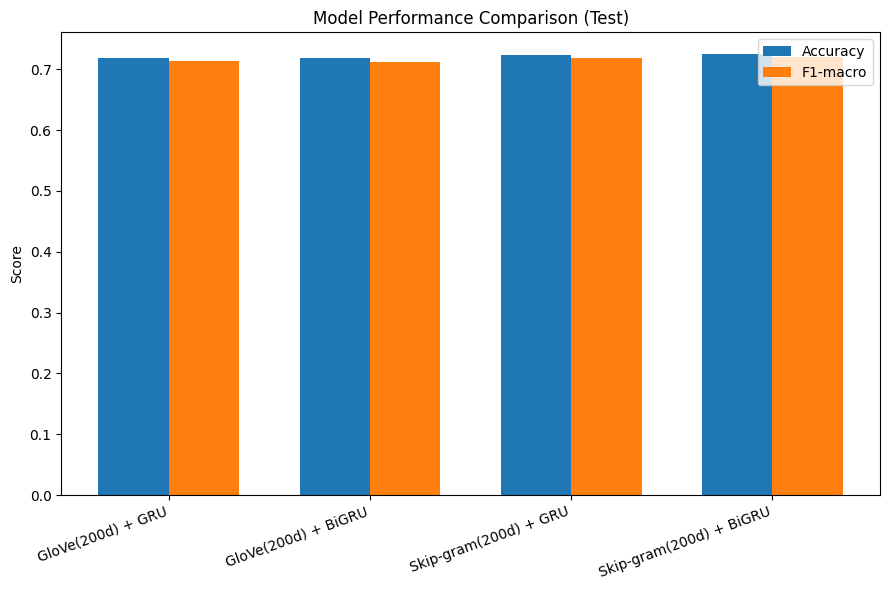

In [ ]:
plt.figure(figsize=(9,6))
idx = np.arange(len(rows))
width = 0.35
plt.bar(idx,        [r["Accuracy"]   for r in rows], width, label="Accuracy")
plt.bar(idx + width,[r["F1-macro"]   for r in rows], width, label="F1-macro")
plt.xticks(idx + width/2, [r["Model"] for r in rows], rotation=20, ha="right")
plt.ylabel("Score")
plt.title("Model Performance Comparison (Test)")
plt.legend()
plt.tight_layout()
plt.show()


=== GloVe(200d) + GRU — Classification Report ===
              precision    recall  f1-score   support

     class_0     0.6492    0.4783    0.5508      6000
     class_1     0.8205    0.8700    0.8445      6000
     class_2     0.5887    0.4982    0.5397      6000
     class_3     0.7068    0.6982    0.7024      6000
     class_4     0.6891    0.7925    0.7372      5999
     class_5     0.7280    0.8178    0.7703      6000
     class_6     0.7576    0.7933    0.7751      6000
     class_7     0.7012    0.7765    0.7370      6000
     class_8     0.6143    0.5873    0.6005      6000
     class_9     0.8863    0.8728    0.8795      6000

    accuracy                         0.7185     59999
   macro avg     0.7142    0.7185    0.7137     59999
weighted avg     0.7142    0.7185    0.7137     59999



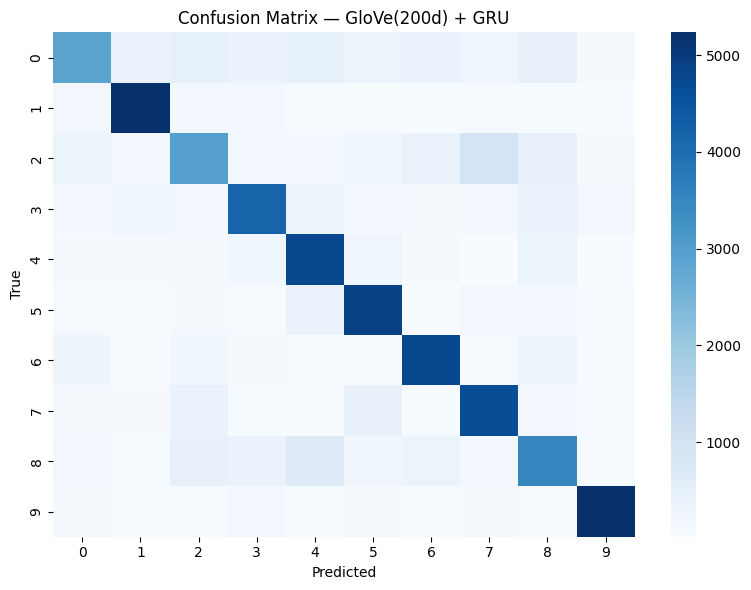


=== GloVe(200d) + BiGRU — Classification Report ===
              precision    recall  f1-score   support

     class_0     0.6371    0.4833    0.5497      6000
     class_1     0.8203    0.8717    0.8452      6000
     class_2     0.5979    0.4773    0.5309      6000
     class_3     0.6986    0.7082    0.7034      6000
     class_4     0.6834    0.7973    0.7360      5999
     class_5     0.7400    0.8085    0.7728      6000
     class_6     0.7570    0.7943    0.7752      6000
     class_7     0.6680    0.8057    0.7304      6000
     class_8     0.6495    0.5562    0.5992      6000
     class_9     0.8810    0.8773    0.8792      6000

    accuracy                         0.7180     59999
   macro avg     0.7133    0.7180    0.7122     59999
weighted avg     0.7133    0.7180    0.7122     59999



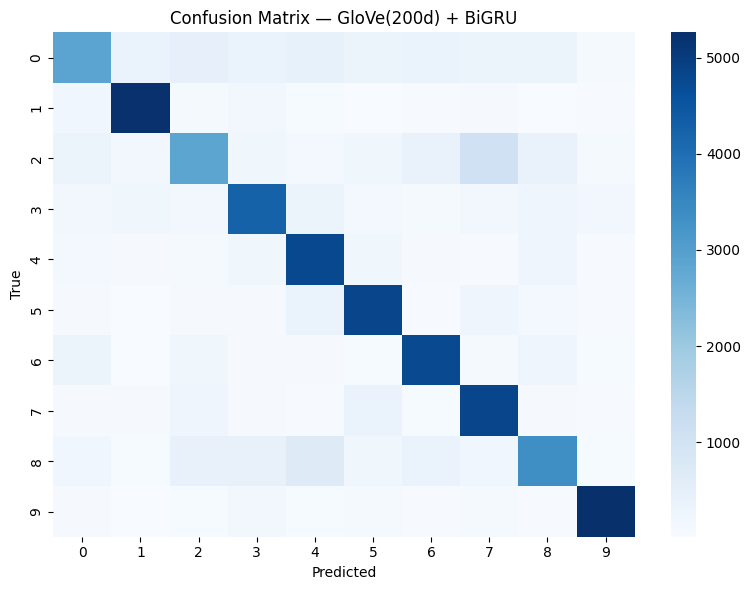


=== Skip-gram(200d) + GRU — Classification Report ===
              precision    recall  f1-score   support

     class_0     0.6507    0.4937    0.5614      6000
     class_1     0.8189    0.8793    0.8480      6000
     class_2     0.6018    0.4932    0.5421      6000
     class_3     0.7071    0.7122    0.7096      6000
     class_4     0.7070    0.7940    0.7480      5999
     class_5     0.7527    0.8182    0.7841      6000
     class_6     0.7008    0.8407    0.7644      6000
     class_7     0.7171    0.7732    0.7441      6000
     class_8     0.6536    0.5557    0.6007      6000
     class_9     0.8750    0.8775    0.8763      6000

    accuracy                         0.7237     59999
   macro avg     0.7185    0.7237    0.7179     59999
weighted avg     0.7185    0.7237    0.7179     59999



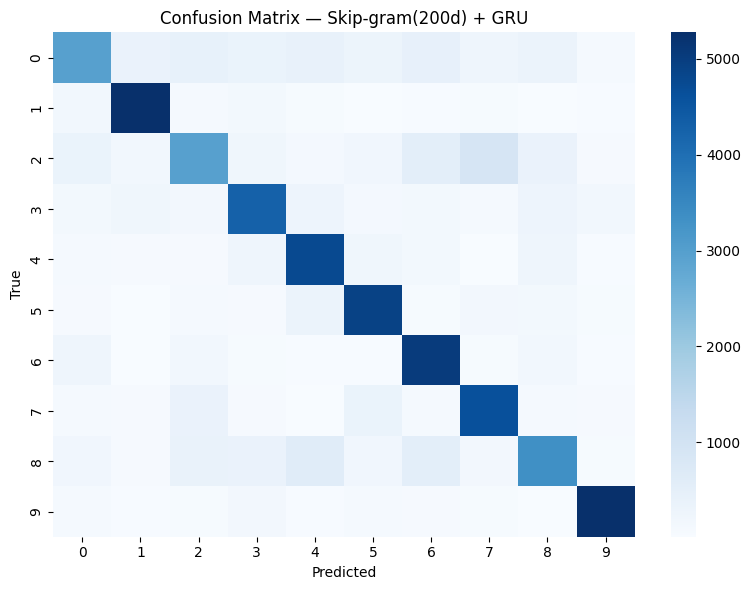


=== Skip-gram(200d) + BiGRU — Classification Report ===
              precision    recall  f1-score   support

     class_0     0.6500    0.4970    0.5633      6000
     class_1     0.8236    0.8792    0.8505      6000
     class_2     0.5792    0.5230    0.5497      6000
     class_3     0.7056    0.7045    0.7050      6000
     class_4     0.7064    0.7980    0.7494      5999
     class_5     0.7587    0.8205    0.7884      6000
     class_6     0.7488    0.8015    0.7743      6000
     class_7     0.7171    0.7690    0.7422      6000
     class_8     0.6394    0.5677    0.6014      6000
     class_9     0.8627    0.8840    0.8732      6000

    accuracy                         0.7244     59999
   macro avg     0.7191    0.7244    0.7197     59999
weighted avg     0.7191    0.7244    0.7197     59999



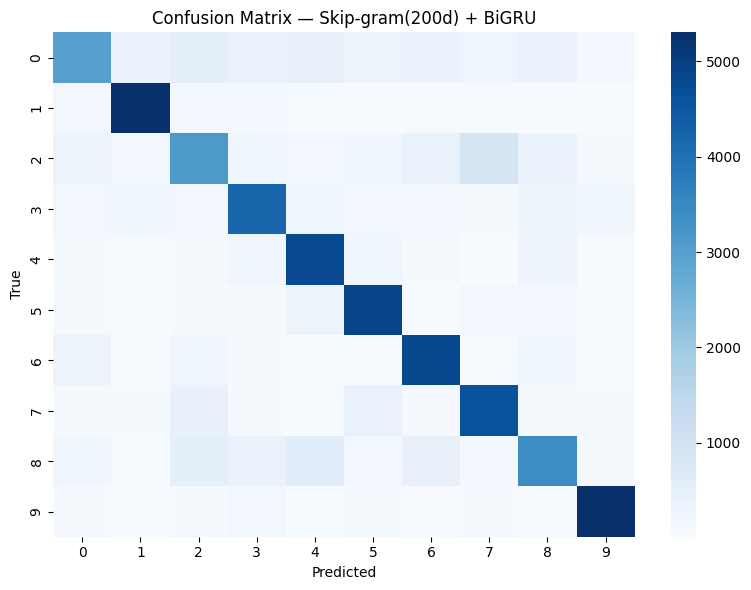

In [ ]:
# Confusion matrices & classification reports
for r in rows:
    print(f"\n=== {r['Model']} — Classification Report ===\n{r['Report']}")
    plot_cm(r["CM"], f"Confusion Matrix — {r['Model']}")

Vanilla RNN and Vanilla BiRNN

In [ ]:
# GPU is recommended for training (Runtime → Change runtime type → T4 GPU) # not important
#was implemented to judge the envioremnet
#angshu 8th
!pip -q install -U tensorflow scikit-learn

import os, numpy as np, tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

print("TF version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.7/620.7 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 77.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tf-keras 2.19.0 requires tensorflow<2.20,>=2.19, but you have tensorflow 2.20.0 which is incompatible.
tensorflow-text 2.19.0 requires tensorflow<2.20,>=2.19.0, but you have tensorflow 2.20.0 which is incompatible.
tensorflow-decision-forests 1.12.0 requires tensorflow==2.19.0, but you have tensorflow 2.20.0 which is incompatible.
tsfresh 0.21.1 requires scipy>=1.14.0; python_version >= "3.10", but you have scipy 1.13.1 which is incompatible.
TF version: 2.19.0
GPU: []


In [ ]:
#extar precausion
#angshu 9th

glove_matrix= glove_matrix
skipgram_matrix  = skipgram_matrix

# infer basics
max_len = X_train.shape[1]
num_classes = int(np.unique(np.concatenate([y_train, y_val, y_test])).size)
print("max_len:", max_len, "num_classes:", num_classes)


max_len: 150 num_classes: 10


Best hyper parameters for Rnn that was tuned through rigours testing:  units=128, dropout=0.2, spatial_dropout=0.2,dense_units=128, lr=1e-3, clipnorm=1.0, embedding_trainable=False.

Available Best hyper parameters for biRnn that was tuned through rigours testing:  units_per_dir=64, dropout=0.2, spatial_dropout=0.2,merge_mode="concat", dense_units=128, lr=1e-3,clipnorm=1.0, embedding_trainable=False

Note: Due hardware limlitation We were limited we were kept units_per_dir=64 instead of 128.

In [ ]:
#Angshu 10th
def build_model_rnn(embedding_matrix, max_len, num_classes,
                    units=128, dropout=0.2, spatial_dropout=0.2,
                    dense_units=128, lr=1e-3, clipnorm=1.0, embedding_trainable=False):
    """Vanilla SimpleRNN classifier with frozen pretrained embeddings."""
    vocab_size, embed_dim = embedding_matrix.shape

    inp = layers.Input(shape=(max_len,), dtype="int32")
    x = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim,
                         weights=[embedding_matrix], input_length=max_len,
                         mask_zero=True, trainable=embedding_trainable, name="emb")(inp)
    if spatial_dropout:
        x = layers.SpatialDropout1D(spatial_dropout)(x)

    x = layers.SimpleRNN(units, dropout=dropout, recurrent_dropout=0.0,
                         return_sequences=False)(x)

    if dense_units:
        x = layers.Dense(dense_units, activation="relu")(x)
        x = layers.Dropout(0.3)(x)

    out = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)  # float32 for mixed precision safety
    model = models.Model(inp, out)
    opt = tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=clipnorm)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def build_model_birnn(embedding_matrix, max_len, num_classes,
                      units_per_dir=64, dropout=0.2, spatial_dropout=0.2,
                      merge_mode="concat", dense_units=128, lr=1e-3,
                      clipnorm=1.0, embedding_trainable=False):
    """Vanilla Bidirectional(SimpleRNN) with frozen pretrained embeddings."""
    vocab_size, embed_dim = embedding_matrix.shape

    inp = layers.Input(shape=(max_len,), dtype="int32")
    x = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim,
                         weights=[embedding_matrix], input_length=max_len,
                         mask_zero=True, trainable=embedding_trainable, name="emb")(inp)
    if spatial_dropout:
        x = layers.SpatialDropout1D(spatial_dropout)(x)

    rnn = layers.SimpleRNN(units_per_dir, dropout=dropout, recurrent_dropout=0.0,
                           return_sequences=False)
    x = layers.Bidirectional(rnn, merge_mode=merge_mode)(x)

    if dense_units:
        x = layers.Dense(dense_units, activation="relu")(x)
        x = layers.Dropout(0.3)(x)

    out = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)
    model = models.Model(inp, out)
    opt = tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=clipnorm)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model
#Analysis by Angshu

'''Best hyper parameters for Rnn that was tuned through rigours testing: units=128, dropout=0.2, spatial_dropout=0.2,dense_units=128, lr=1e-3, clipnorm=1.0, embedding_trainable=False.

Available Best hyper parameters for biRnn that was tuned through rigours testing: units_per_dir=64, dropout=0.2, spatial_dropout=0.2,merge_mode="concat", dense_units=128, lr=1e-3,clipnorm=1.0, embedding_trainable=False

Note: Due hardware limlitation We were limited we were kept units_per_dir=64 instead of 128.'''


In [ ]:
def train_and_eval(model, X_train, y_train, X_val, y_val, X_test, y_test,
                   batch_size=64, epochs=12, name="Model"):
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    rlrop = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        batch_size=batch_size,
        epochs=epochs,
        shuffle=True,
        callbacks=[es, rlrop],
        verbose=1
    )

    # Evaluate
    pred = model.predict(X_test, verbose=0).argmax(axis=1)
    acc = accuracy_score(y_test, pred)
    f1  = f1_score(y_test, pred, average="macro")
    print(f"\n[{name}] TEST accuracy: {acc:.4f} | TEST F1 (macro): {f1:.4f}")
    print(classification_report(y_test, pred))
    print("Confusion matrix:\n", confusion_matrix(y_test, pred))
    return {"name": name, "acc": acc, "f1_macro": f1, "pred": pred, "history": history}


# ===== RUNS =====
results = {}

# 1) GloVe-200d — Vanilla RNN
model_glove_rnn = build_model_rnn(glove_matrix, max_len, num_classes,
                                  units=128, dropout=0.2, spatial_dropout=0.2,
                                  dense_units=128, lr=1e-3, clipnorm=1.0,
                                  embedding_trainable=False)
results["glove_rnn"] = train_and_eval(model_glove_rnn, X_train, y_train, X_val, y_val, X_test, y_test,
                                      batch_size=64, epochs=12, name="GloVe-200d | SimpleRNN")

# 2) GloVe-200d — Vanilla BiRNN
model_glove_birnn = build_model_birnn(glove_matrix, max_len, num_classes,
                                      units_per_dir=64, dropout=0.2, spatial_dropout=0.2,
                                      merge_mode="concat", dense_units=128, lr=1e-3,
                                      clipnorm=1.0, embedding_trainable=False)
results["glove_birnn"] = train_and_eval(model_glove_birnn, X_train, y_train, X_val, y_val, X_test, y_test,
                                        batch_size=64, epochs=12, name="GloVe-200d | BiRNN(SimpleRNN)")

# 3) Skip-gram — Vanilla RNN
model_skip_rnn = build_model_rnn(skipgram_matrix, max_len, num_classes,
                                 units=128, dropout=0.2, spatial_dropout=0.2,
                                 dense_units=128, lr=1e-3, clipnorm=1.0,
                                 embedding_trainable=False)
results["skipgram_rnn"] = train_and_eval(model_skip_rnn, X_train, y_train, X_val, y_val, X_test, y_test,
                                         batch_size=64, epochs=12, name="Skip-gram | SimpleRNN")

# 4) Skip-gram — Vanilla BiRNN
model_skip_birnn = build_model_birnn(skipgram_matrix, max_len, num_classes,
                                     units_per_dir=64, dropout=0.2, spatial_dropout=0.2,
                                     merge_mode="concat", dense_units=128, lr=1e-3,
                                     clipnorm=1.0, embedding_trainable=False)
results["skipgram_birnn"] = train_and_eval(model_skip_birnn, X_train, y_train, X_val, y_val, X_test, y_test,
                                           batch_size=64, epochs=12, name="Skip-gram | BiRNN(SimpleRNN)")

# Quick summary
for k, v in results.items():
    print(f"{k:18s}  Acc: {v['acc']:.4f}  F1_macro: {v['f1_macro']:.4f}")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 580s 164ms/step - accuracy: 0.4326 - loss: 1.7168 - val_accuracy: 0.5793 - val_loss: 1.4160 - learning_rate: 0.0010
Epoch 2/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 527s 150ms/step - accuracy: 0.5449 - loss: 1.4828 - val_accuracy: 0.5960 - val_loss: 1.3433 - learning_rate: 0.0010
Epoch 3/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 602s 162ms/step - accuracy: 0.5568 - loss: 1.4473 - val_accuracy: 0.6008 - val_loss: 1.3087 - learning_rate: 0.0010
Epoch 4/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 614s 160ms/step - accuracy: 0.5654 - loss: 1.4206 - val_accuracy: 0.6009 - val_loss: 1.3067 - learning_rate: 0.0010
Epoch 5/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 578s 164ms/step - accuracy: 0.5663 - loss: 1.4135 - val_accuracy: 0.5984 - val_loss: 1.3089 - learning_rate: 0.0010
Epoch 6/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 523s 149ms/step - accuracy: 0.5811 - loss: 1.3645 - val_accuracy: 0.6215 - val_loss: 1.2376 - learning_rate: 5.0000e-04
Epoch 7/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 594s 1

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 512s 145ms/step - accuracy: 0.4862 - loss: 1.5383 - val_accuracy: 0.6399 - val_loss: 1.1455 - learning_rate: 0.0010
Epoch 2/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 558s 144ms/step - accuracy: 0.6078 - loss: 1.2348 - val_accuracy: 0.6506 - val_loss: 1.1026 - learning_rate: 0.0010
Epoch 3/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 572s 147ms/step - accuracy: 0.6189 - loss: 1.2078 - val_accuracy: 0.6576 - val_loss: 1.0862 - learning_rate: 0.0010
Epoch 4/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 513s 147ms/step - accuracy: 0.6245 - loss: 1.1881 - val_accuracy: 0.6619 - val_loss: 1.0718 - learning_rate: 0.0010
Epoch 5/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 553s 144ms/step - accuracy: 0.6291 - loss: 1.1725 - val_accuracy: 0.6585 - val_loss: 1.0647 - learning_rate: 0.0010
Epoch 6/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 570s 146ms/step - accuracy: 0.6306 - loss: 1.1662 - val_accuracy: 0.6562 - val_loss: 1.0903 - learning_rate: 0.0010
Epoch 7/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 554s 144ms

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 534s 152ms/step - accuracy: 0.4642 - loss: 1.6358 - val_accuracy: 0.6109 - val_loss: 1.3661 - learning_rate: 0.0010
Epoch 2/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 539s 154ms/step - accuracy: 0.5656 - loss: 1.4333 - val_accuracy: 0.6272 - val_loss: 1.2668 - learning_rate: 0.0010
Epoch 3/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 598s 164ms/step - accuracy: 0.5792 - loss: 1.3924 - val_accuracy: 0.6291 - val_loss: 1.2287 - learning_rate: 0.0010
Epoch 4/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 579s 152ms/step - accuracy: 0.5830 - loss: 1.3804 - val_accuracy: 0.6163 - val_loss: 1.2657 - learning_rate: 0.0010
Epoch 5/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 571s 163ms/step - accuracy: 0.5995 - loss: 1.3190 - val_accuracy: 0.6363 - val_loss: 1.1881 - learning_rate: 5.0000e-04
Epoch 6/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 614s 161ms/step - accuracy: 0.6098 - loss: 1.2868 - val_accuracy: 0.6551 - val_loss: 1.1459 - learning_rate: 5.0000e-04
Epoch 7/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 56

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 517s 144ms/step - accuracy: 0.5269 - loss: 1.4214 - val_accuracy: 0.6698 - val_loss: 1.0384 - learning_rate: 0.0010
Epoch 2/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 686s 180ms/step - accuracy: 0.6319 - loss: 1.1613 - val_accuracy: 0.6750 - val_loss: 1.0195 - learning_rate: 0.0010
Epoch 3/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 564s 146ms/step - accuracy: 0.6395 - loss: 1.1371 - val_accuracy: 0.6792 - val_loss: 1.0118 - learning_rate: 0.0010
Epoch 4/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 696s 185ms/step - accuracy: 0.6470 - loss: 1.1165 - val_accuracy: 0.6747 - val_loss: 1.0127 - learning_rate: 0.0010
Epoch 5/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 546s 146ms/step - accuracy: 0.6545 - loss: 1.0887 - val_accuracy: 0.6887 - val_loss: 0.9674 - learning_rate: 5.0000e-04
Epoch 6/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 508s 145ms/step - accuracy: 0.6598 - loss: 1.0696 - val_accuracy: 0.6889 - val_loss: 0.9648 - learning_rate: 5.0000e-04
Epoch 7/12
3501/3501 ━━━━━━━━━━━━━━━━━━━━ 56

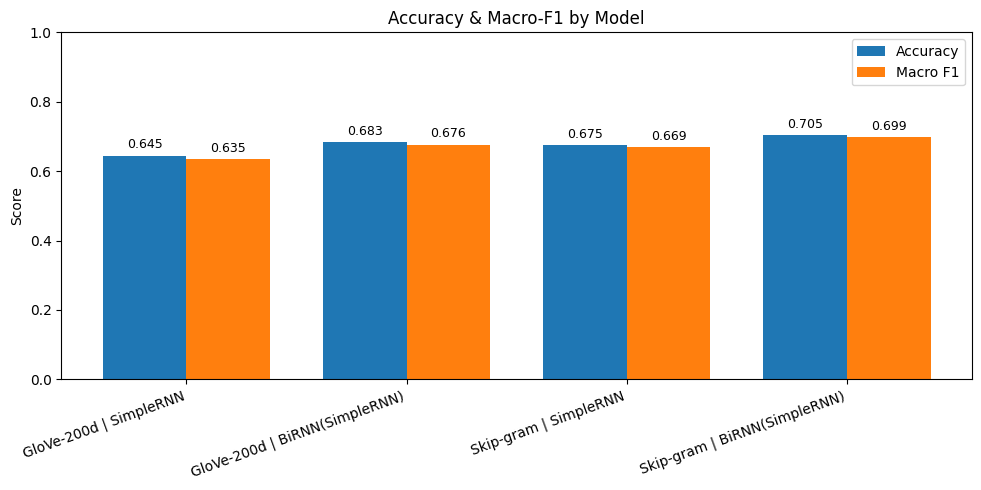

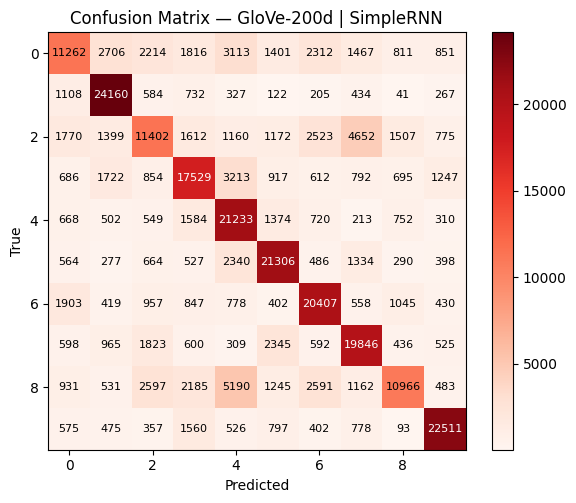

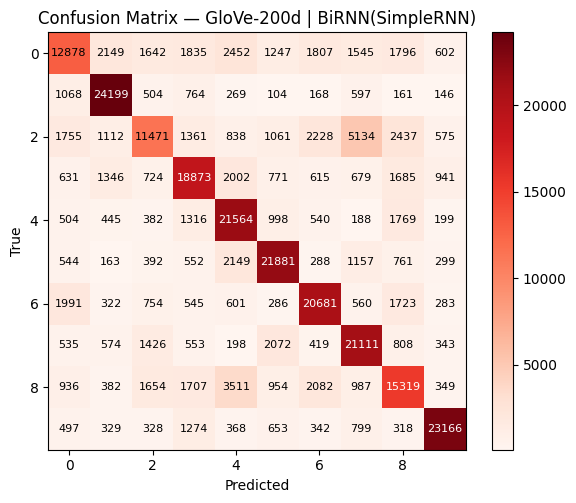

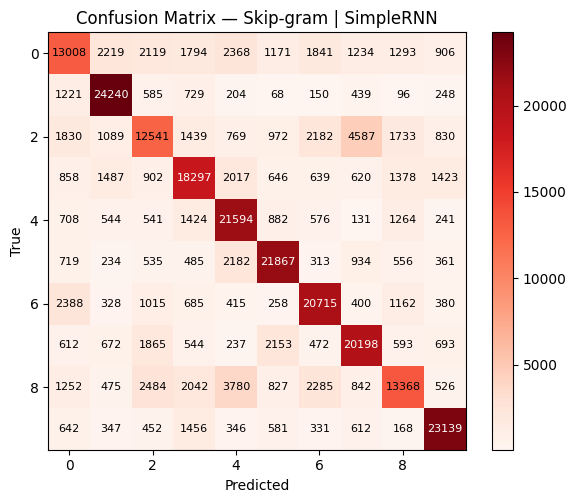

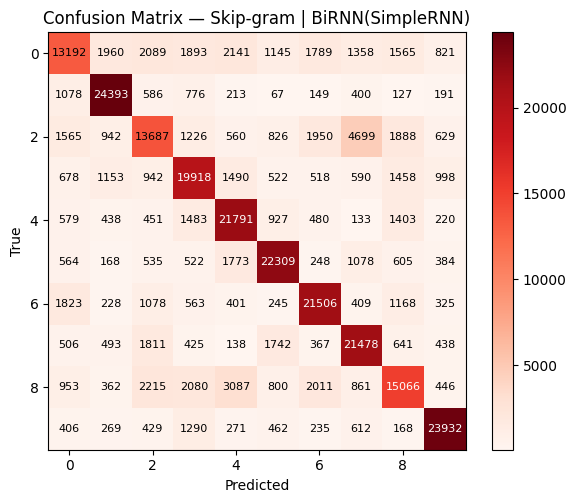

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

# ---- which results to plot (left name = pretty label shown on plots, right key = results[...] key) ---
pairs = [
    ("GloVe-200d | SimpleRNN",        "glove_rnn"),
    ("GloVe-200d | BiRNN(SimpleRNN)", "glove_birnn"),
    ("Skip-gram | SimpleRNN",         "skipgram_rnn"),
    ("Skip-gram | BiRNN(SimpleRNN)",  "skipgram_birnn"),
]

# ---- gather metrics and confusion matrices ----
labels   = []
accs     = []
f1s      = []
cms      = {}

for pretty, key in pairs:
    labels.append(pretty)
    pred = results[key]["pred"]
    acc  = results[key].get("acc", accuracy_score(y_test, pred))
    f1   = results[key].get("f1_macro", f1_score(y_test, pred, average="macro"))
    accs.append(acc)
    f1s.append(f1)
    cms[pretty] = confusion_matrix(y_test, pred)

# ---- single grouped barplot: blue = accuracy, orange = macro-F1 ----
x = np.arange(len(labels))
w = 0.38  # bar width

plt.figure(figsize=(10,5))
b1 = plt.bar(x - w/2, accs, width=w, label="Accuracy", color="tab:blue")
b2 = plt.bar(x + w/2, f1s,  width=w, label="Macro F1", color="tab:orange")

plt.xticks(x, labels, rotation=20, ha="right")
plt.ylim(0, 1.0)
plt.ylabel("Score")
plt.title("Accuracy & Macro-F1 by Model")
plt.legend()

# annotate values on bars
def _annotate(bars):
    for bar in bars:
        h = bar.get_height()
        plt.annotate(f"{h:.3f}",
                     xy=(bar.get_x() + bar.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points",
                     ha="center", va="bottom", fontsize=9)
_annotate(b1); _annotate(b2)

plt.tight_layout()
plt.show()

# ---- confusion matrices with a clearer colormap ----
# choose a perceptually-uniform map; 'magma' has good contrast
for name, cm in cms.items():
    plt.figure(figsize=(6,5))
    im = plt.imshow(cm, interpolation="nearest", cmap="Reds")
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    cbar = plt.colorbar(im)

    # annotate counts with readable text color
    vmax = cm.max() if cm.size else 1
    thresh = vmax * 0.6
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            v = cm[i, j]
            txt_color = "white" if v >= thresh else "black"
            plt.text(j, i, f"{v}", ha="center", va="center", color=txt_color, fontsize=8)

    plt.tight_layout()
    plt.show()